# Lab 4 — Assignment


**Based on:** Lab-4-b (Bernoulli, Binomial, Poisson, Normal, Uniform)


---

### Instructions

1. Run the **Setup** cell first. Do not modify it.
2. There are **10 questions** — two on each distribution. Attempt **all** of them.
3. Every question has three parts:
   - **(a)** and **(b)** — work these out **by hand** and type your working in the *Written answer* cell.
   - **(c)** — write **Python code** in the blank code cell provided and produce the plot asked for.
4. Use `DISCRETE_COLOR` for discrete plots (bars) and `CONTINUOUS_COLOR` for continuous plots (curves).
5. Every plot must have an **x-label, y-label and a title**. Marks are deducted for unlabelled plots.
6. Round all probabilities to **4 decimal places**.
7. Save the notebook with all outputs visible before submitting.

### Marks distribution

| Section | Questions | Marks each | Total |
|---|---|---|---|
| A — Bernoulli | Q1, Q2 | 5 | 10 |
| B — Binomial | Q3, Q4 | 5 | 10 |
| C — Poisson | Q5, Q6 | 5 | 10 |
| D — Normal | Q7, Q8 | 5 | 10 |
| E — Uniform | Q9, Q10 | 5 | 10 |
| | | **Total** | **50** |

### Quick reference — which function do I need?

| Task | `scipy.stats` call |
|---|---|
| $P(X = k)$, discrete | `.pmf(k, ...)` |
| $f(x)$, continuous | `.pdf(x, ...)` |
| $P(X \le x)$ | `.cdf(x, ...)` |
| $P(X > x)$ | `.sf(x, ...)` |
| Value with given $P(X \le x)$ | `.ppf(prob, ...)` |
| Mean / variance | `.mean(...)`, `.var(...)` |
| Random samples | `.rvs(..., size=n, random_state=seed)` |

---

## Setup
Run this cell first — do not change it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from math import comb, factorial, exp, sqrt

DISCRETE_COLOR = "#0E9F9A"     # teal   -> discrete distributions
CONTINUOUS_COLOR = "#E4572E"   # orange -> continuous distributions
HIGHLIGHT_COLOR = "#F4A261"    # use this to highlight a bar or a shaded area

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("Setup complete — you are ready to start.")

Setup complete — you are ready to start.


---
# Part A — Bernoulli distribution
*Recall:* $P(X=x) = p^x(1-p)^{1-x}$ for $x \in \{0,1\}$, $\;E[X]=p$, $\;Var(X)=p(1-p)$.

## Q1. The library gate scanner 

> 📚 The RFID gate at the college library reads a student's ID card correctly on the **first tap 92%** of the time. One student taps her card once.
>
> Let $X = 1$ if the card is read on the first tap, and $X = 0$ if it is not.
>
> **(a)** State the value of $p$ and find $P(X=1)$ and $P(X=0)$.
> **(b)** Find the mean and the variance of $X$, showing the substitution into the formulas.
> **(c)** Write Python code that:
> - builds the PMF of $X$ using `stats.bernoulli.pmf`,
> - draws a **bar chart** of the distribution in `DISCRETE_COLOR` with the ticks labelled `"Not read (0)"` and `"Read (1)"`,
> - writes the probability value on top of each bar,
> - prints the mean and the variance obtained from `scipy`, and checks that they match your hand answers in (b).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** Here X is a Bernoulli trial with p = P(card read on first tap) = 0.92.
> 
> P(X=1) = p = 0.92
> 
> P(X=0) = 1 - p = 1 - 0.92 = 0.08
> 
> **(b)** Mean: E[X] = p = 0.92
> 
> Variance: Var(X) = p(1-p) = 0.92 × 0.08 = 0.0736


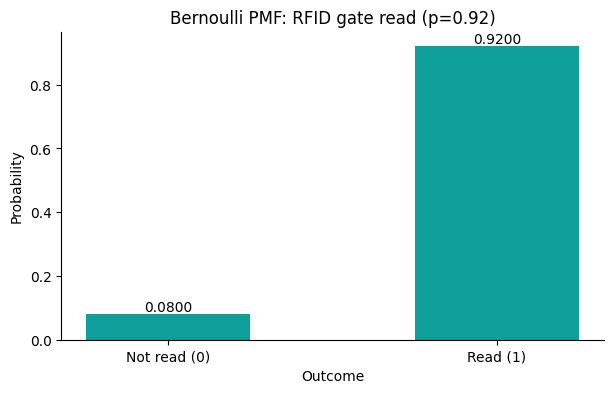

scipy mean = 0.9200, scipy variance = 0.0736
Matches hand answers: mean=0.9200, variance=0.0736


In [2]:
p = 0.92
x_vals = np.array([0, 1])
pmf = stats.bernoulli.pmf(x_vals, p)

fig, ax = plt.subplots()
bars = ax.bar(x_vals, pmf, color=DISCRETE_COLOR, width=0.5)
ax.set_xticks(x_vals)
ax.set_xticklabels(["Not read (0)", "Read (1)"])
for xi, pi in zip(x_vals, pmf):
    ax.text(xi, pi + 0.01, f"{pi:.4f}", ha="center")
ax.set_xlabel("Outcome")
ax.set_ylabel("Probability")
ax.set_title("Bernoulli PMF: RFID gate read (p=0.92)")
plt.show()

mean = stats.bernoulli.mean(p)
var = stats.bernoulli.var(p)
print(f"scipy mean = {mean:.4f}, scipy variance = {var:.4f}")
print("Matches hand answers: mean=0.9200, variance=0.0736")

## Q2. Estimating $p$ from attendance data &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 👆 A biometric attendance device records whether a student's fingerprint is accepted on the **first attempt**. Over one semester the device logged **2,000 scans**, of which **1,740** were accepted on the first attempt. Treat one scan as a single Bernoulli trial with $X=1$ for *accepted*.
>
> **(a)** Estimate $p$ from the data and write down the full PMF $P(X=x)$ with the estimated value substituted in.
> **(b)** Find the mean and variance. Then answer: for what value of $p$ would the variance of a Bernoulli variable be the **largest possible**, and what is that largest value? Justify your answer using the formula $Var(X)=p(1-p)$.
> **(c)** Write Python code that:
> - simulates 2,000 Bernoulli trials with your estimated $p$ using `stats.bernoulli.rvs(..., random_state=42)`,
> - prints the **simulated proportion** of successes next to the theoretical $p$,
> - plots the **theoretical PMF and the simulated relative frequencies side by side** as grouped bars with a legend,
> - plots $Var(X)=p(1-p)$ against $p$ for $p$ from 0 to 1 in a **second figure**, and marks the maximum point with a marker and an annotation.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** Estimated p = (accepted)/(total) = 1740/2000 = 0.87
> 
> PMF: P(X=x) = 0.87^x (0.13)^(1-x), for x ∈ {0,1}
> 
> **(b)** Mean: E[X] = p = 0.87
> 
> Variance: Var(X) = p(1-p) = 0.87 × 0.13 = 0.1131
> 
> Var(X) = p - p² is maximised where d/dp[p - p²] = 1 - 2p = 0 ⟹ p = 0.5.
> 
> At p = 0.5, Var(X) = 0.5 × 0.5 = 0.25, which is the largest possible variance for a Bernoulli variable.


Simulated proportion of successes: 0.8675
Theoretical p: 0.8700


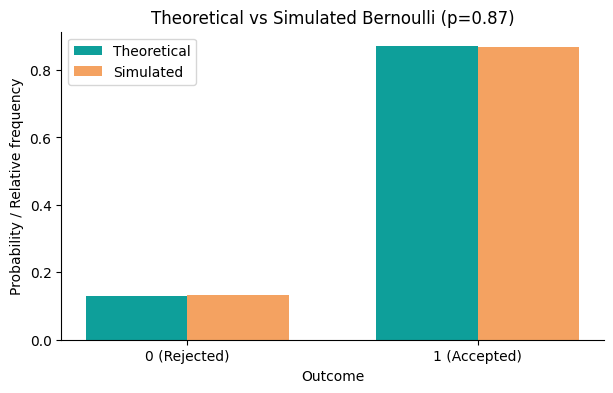

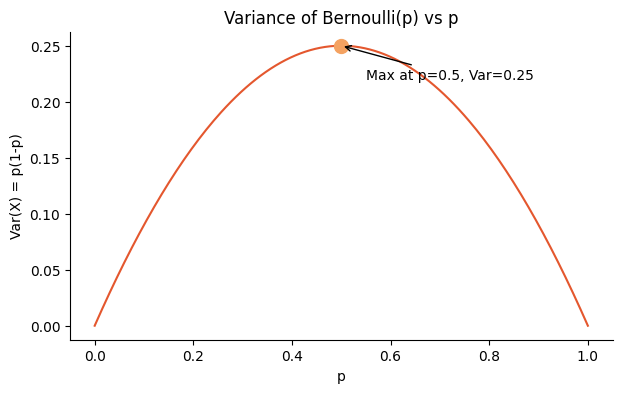

In [3]:
p_hat = 1740 / 2000
n_trials = 2000

sim = stats.bernoulli.rvs(p_hat, size=n_trials, random_state=42)
sim_prop = sim.mean()
print(f"Simulated proportion of successes: {sim_prop:.4f}")
print(f"Theoretical p: {p_hat:.4f}")

theo_pmf = stats.bernoulli.pmf([0, 1], p_hat)
sim_freq = [1 - sim_prop, sim_prop]

fig, ax = plt.subplots()
xpos = np.arange(2)
width = 0.35
ax.bar(xpos - width/2, theo_pmf, width=width, color=DISCRETE_COLOR, label="Theoretical")
ax.bar(xpos + width/2, sim_freq, width=width, color=HIGHLIGHT_COLOR, label="Simulated")
ax.set_xticks(xpos)
ax.set_xticklabels(["0 (Rejected)", "1 (Accepted)"])
ax.set_xlabel("Outcome")
ax.set_ylabel("Probability / Relative frequency")
ax.set_title("Theoretical vs Simulated Bernoulli (p=0.87)")
ax.legend()
plt.show()

p_range = np.linspace(0, 1, 200)
var_range = p_range * (1 - p_range)
max_p = 0.5
max_var = 0.25

fig2, ax2 = plt.subplots()
ax2.plot(p_range, var_range, color=CONTINUOUS_COLOR)
ax2.plot(max_p, max_var, "o", color=HIGHLIGHT_COLOR, markersize=10)
ax2.annotate(f"Max at p={max_p}, Var={max_var}", xy=(max_p, max_var),
             xytext=(0.55, 0.22), arrowprops=dict(arrowstyle="->"))
ax2.set_xlabel("p")
ax2.set_ylabel("Var(X) = p(1-p)")
ax2.set_title("Variance of Bernoulli(p) vs p")
plt.show()

---
# Part B — Binomial distribution
*Recall:* $P(X=k) = \binom{n}{k}p^k(1-p)^{n-k}$, $\;E[X]=np$, $\;Var(X)=np(1-p)$.

## Q3. Guessing a multiple-choice quiz &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📝 An online quiz has **12 multiple-choice questions**, each with **4 options** and exactly one correct answer. A student who has not studied guesses every answer at random. Let $X$ = number of questions answered correctly.
>
> **(a)** State $n$ and $p$, check that the **BINS** conditions hold, and compute $P(X=5)$ **by hand**, showing the value of $\binom{12}{5}$.
> **(b)** Find the mean and the variance of $X$.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
>

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** n = 12, p = 1/4 = 0.25 (each guess independent, only 2 outcomes: correct/incorrect, fixed n, constant p — BINS holds: Binary, Independent, Number fixed, Same probability).
> 
> C(12,5) = 792
> 
> P(X=5) = C(12,5) p^5 (1-p)^7 = 792 × (0.25)^5 × (0.75)^7 ≈ 0.1032
> 
> **(b)** Mean: E[X] = np = 12 × 0.25 = 3
> 
> Variance: Var(X) = np(1-p) = 12 × 0.25 × 0.75 = 2.25


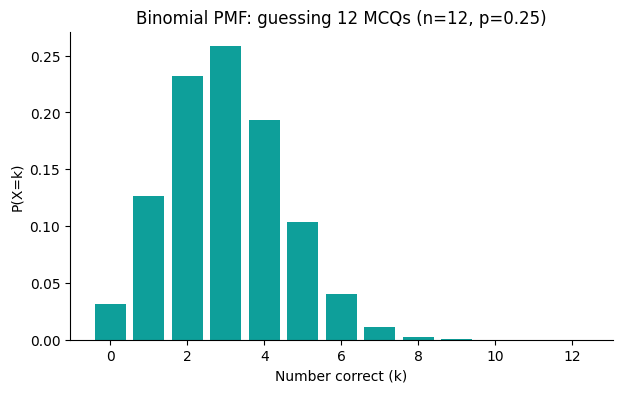

P(X=5) = 0.1032
mean = 3.0000, variance = 2.2500


In [4]:
n, p = 12, 0.25
k = np.arange(0, 13)
pmf = stats.binom.pmf(k, n, p)

fig, ax = plt.subplots()
ax.bar(k, pmf, color=DISCRETE_COLOR)
ax.set_xlabel("Number correct (k)")
ax.set_ylabel("P(X=k)")
ax.set_title("Binomial PMF: guessing 12 MCQs (n=12, p=0.25)")
plt.show()

print(f"P(X=5) = {stats.binom.pmf(5, n, p):.4f}")
print(f"mean = {stats.binom.mean(n,p):.4f}, variance = {stats.binom.var(n,p):.4f}")

#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> 
> 
> 
> 
> 


---
# Part C — Poisson distribution
*Recall:* $P(X=k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$, $\;E[X]=Var(X)=\lambda$.

## Q5. Help-desk emails &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 📧 The IT help-desk of a college receives on average **3 emails per hour**. Let $X$ = number of emails received in one hour.
>
> **(a)** Compute $P(X = 0)$ and $P(X = 2)$ **by hand**, showing the substitution into the formula ($e^{-3} \approx 0.0498$).
> **(b)** State the mean and the variance, and explain in one line what is special about them for a Poisson distribution.
> **(c)** Write Python code that:
> - plots the PMF as a bar chart for $k = 0$ to $12$ in `DISCRETE_COLOR`,
> - prints $P(X=0)$, $P(X=2)$ and $P(X \le 5)$,
> - prints the smallest value of $k$ for which $P(X \le k) \ge 0.95$ (use `.ppf` or a loop).

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** λ = 3.
> 
> P(X=0) = e^(-3) λ^0/0! = e^(-3) ≈ 0.0498
> 
> P(X=2) = e^(-3) 3^2/2! = 0.0498 × 9/2 ≈ 0.2240
> 
> **(b)** Mean = Variance = λ = 3. For a Poisson distribution the mean always equals the variance — both are governed by the single parameter λ.


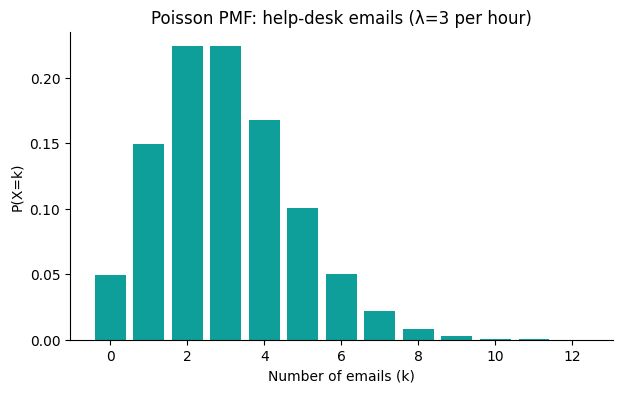

P(X=0) = 0.0498
P(X=2) = 0.2240
P(X<=5) = 0.9161
Smallest k with P(X<=k) >= 0.95: k = 6, P(X<=k) = 0.9665


In [5]:
lam = 3
k = np.arange(0, 13)
pmf = stats.poisson.pmf(k, lam)

fig, ax = plt.subplots()
ax.bar(k, pmf, color=DISCRETE_COLOR)
ax.set_xlabel("Number of emails (k)")
ax.set_ylabel("P(X=k)")
ax.set_title("Poisson PMF: help-desk emails (λ=3 per hour)")
plt.show()

p0 = stats.poisson.pmf(0, lam)
p2 = stats.poisson.pmf(2, lam)
p_le5 = stats.poisson.cdf(5, lam)
print(f"P(X=0) = {p0:.4f}")
print(f"P(X=2) = {p2:.4f}")
print(f"P(X<=5) = {p_le5:.4f}")

k_needed = int(stats.poisson.ppf(0.95, lam))
while stats.poisson.cdf(k_needed, lam) < 0.95:
    k_needed += 1
print(f"Smallest k with P(X<=k) >= 0.95: k = {k_needed}, P(X<=k) = {stats.poisson.cdf(k_needed, lam):.4f}")

## Q6. Server errors over a night shift &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> 🖥️ A web server logs errors at an average rate of **1.5 errors per hour**. The night shift runs from 10 pm to 6 am, i.e. **8 hours**.
>
> **(a)** Find the value of $\lambda$ for the **whole 8-hour shift**, and compute by hand the probability of a **clean shift** (zero errors in the 8 hours).
> **(b)** State the mean and variance for the 8-hour window. The on-call engineer is paged if **more than 18 errors** occur in the shift — write the expression for that probability and name the `scipy` function that gives it directly.
> **(c)** Write Python code that:
> - creates **two subplots side by side** — the PMF for the 1-hour window ($\lambda = 1.5$) and the PMF for the 8-hour window — each with its own sensible range of $k$, title and labels,


#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> **(a)** λ (8-hour shift) = 1.5 × 8 = 12.
> 
> P(clean shift) = P(X=0) = e^(-12) × 12^0/0! = e^(-12) ≈ 0.0000061 ≈ 0.0000
> 
> **(b)** Mean = Variance = λ = 12 (for the 8-hour window).
> 
> P(paged) = P(X > 18) = 1 - P(X ≤ 18), obtained directly from `stats.poisson.sf(18, 12)`.


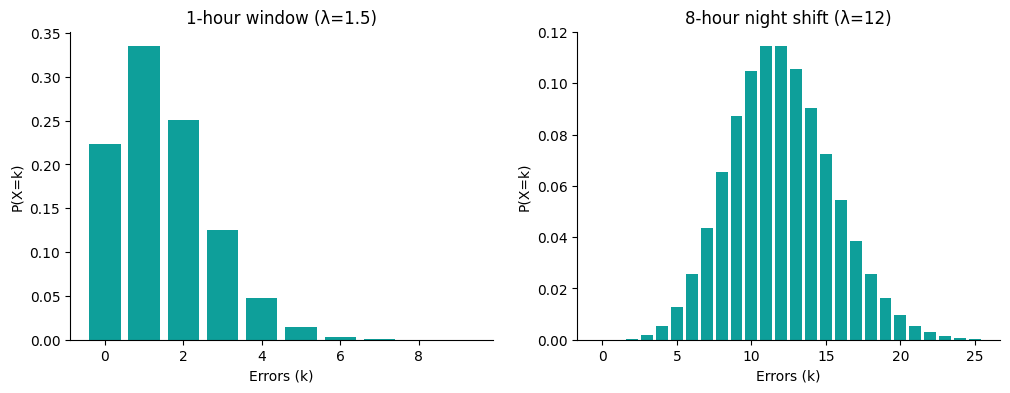

P(clean shift) = 0.0000
mean = variance = 12.0000
P(paged) = P(X>18) = 0.0374  (via stats.poisson.sf(18, lambda))


In [6]:
lam_1hr = 1.5
lam_8hr = 1.5 * 8

k1 = np.arange(0, 10)
k8 = np.arange(0, 26)
pmf_1 = stats.poisson.pmf(k1, lam_1hr)
pmf_8 = stats.poisson.pmf(k8, lam_8hr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(k1, pmf_1, color=DISCRETE_COLOR)
axes[0].set_xlabel("Errors (k)")
axes[0].set_ylabel("P(X=k)")
axes[0].set_title("1-hour window (λ=1.5)")

axes[1].bar(k8, pmf_8, color=DISCRETE_COLOR)
axes[1].set_xlabel("Errors (k)")
axes[1].set_ylabel("P(X=k)")
axes[1].set_title("8-hour night shift (λ=12)")
plt.tight_layout()
plt.show()

p_clean = stats.poisson.pmf(0, lam_8hr)
p_paged = stats.poisson.sf(18, lam_8hr)
print(f"P(clean shift) = {p_clean:.4f}")
print(f"mean = variance = {lam_8hr:.4f}")
print(f"P(paged) = P(X>18) = {p_paged:.4f}  (via stats.poisson.sf(18, lambda))")

---
# Part D — Normal distribution
*Recall:* $f(x)=\dfrac{1}{\sigma\sqrt{2\pi}}e^{-(x-\mu)^2/2\sigma^2}$, $\;Z=\dfrac{X-\mu}{\sigma}$, $\;E[X]=\mu$, $\;Var(X)=\sigma^2$.

## Q7. Battery life of a phone &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🔋 The battery life of a phone model is normally distributed with a mean of **18 hours** and a standard deviation of **1.5 hours**. Let $X$ = battery life of a randomly chosen phone.
>
> **(a)** Compute the **Z-score** for a battery life of 15 hours and say in words what that Z-score means.
> **(b)** Using the 68–95–99.7 rule, state the interval of battery lives that contains about **95%** of the phones. Show how you obtained it.
> **(c)** Write Python code that:
> - generates 400 equally spaced values of $x$ over $\mu \pm 4\sigma$ and computes the PDF,
> - plots the curve in `CONTINUOUS_COLOR` with a title and axis labels,
.

#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** Z = (X - μ)/σ = (15 - 18)/1.5 = -2.0
> 
> This means a battery life of 15 hours is 2 standard deviations below the mean.
> 
> **(b)** By the 68–95–99.7 rule, about 95% of values lie within μ ± 2σ.
> 
> Interval = 18 ± 2(1.5) = [15, 21] hours.


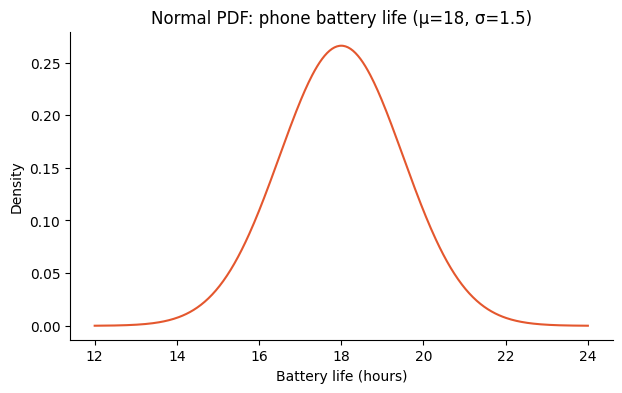

Z-score for 15 hours: -2.0000
95% interval (μ±2σ): [15.0, 21.0] hours


In [7]:
mu, sigma = 18, 1.5
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 400)
pdf = stats.norm.pdf(x, mu, sigma)

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR)
ax.set_xlabel("Battery life (hours)")
ax.set_ylabel("Density")
ax.set_title("Normal PDF: phone battery life (μ=18, σ=1.5)")
plt.show()

z = (15 - mu) / sigma
print(f"Z-score for 15 hours: {z:.4f}")
print(f"95% interval (μ±2σ): [{mu-2*sigma:.1f}, {mu+2*sigma:.1f}] hours")

## Q8. Calibrating a coffee machine &nbsp;&nbsp;<sub>[5 marks] — *harder*</sub>

> ☕ A vending machine fills cups with coffee. The fill volume is normally distributed with a mean of **200 ml**, but the standard deviation is **not known**. The service log shows that **2.5% of cups overflow**, which happens whenever the fill exceeds **210 ml**.
>
> **(a)** Using the standard normal value $z_{0.975} \approx 1.96$, find the standard deviation $\sigma$ of the fill volume. Show the working.
> **(b)** With that $\sigma$, find the volume below which only **1%** of cups fall (the 1st percentile), and state which `scipy` function gives it. A customer complains if the cup holds less than **190 ml** — write the expression for that probability.
> **(c)** Write Python code that:
> - computes $\sigma$ using `stats.norm.ppf` rather than the rounded 1.96,
> - plots the PDF over a sensible range in `CONTINUOUS_COLOR`,



#### ✍️ Written answer (a), (b) and (d) — *type your hand calculation below*

> **(a)** P(X > 210) = 0.025 ⟹ P(Z > (210-200)/σ) = 0.025 ⟹ (210-200)/σ = z_0.975 ≈ 1.96
> 
> σ = 10/1.96 ≈ 5.1020 ml
> 
> **(b)** 1st percentile: x = μ + σ·z_0.01 = norm.ppf(0.01, loc=200, scale=σ) ≈ 188.13 ml — obtained with `stats.norm.ppf`.
> 
> P(complaint) = P(X < 190) = stats.norm.cdf(190, loc=200, scale=σ) ≈ 0.0250


z_0.975 (exact) = 1.9600
sigma = 5.1021 ml


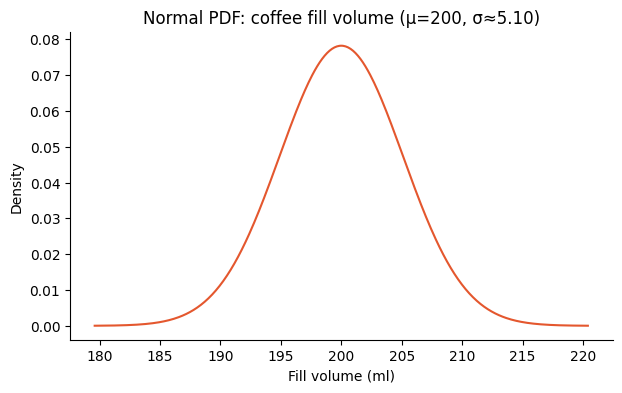

1st percentile = 188.1307 ml (via stats.norm.ppf)
P(X<190) = 0.0250


In [8]:
z_0975 = stats.norm.ppf(0.975)
sigma = 10 / z_0975
print(f"z_0.975 (exact) = {z_0975:.4f}")
print(f"sigma = {sigma:.4f} ml")

x = np.linspace(200 - 4*sigma, 200 + 4*sigma, 400)
pdf = stats.norm.pdf(x, 200, sigma)

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR)
ax.set_xlabel("Fill volume (ml)")
ax.set_ylabel("Density")
ax.set_title(f"Normal PDF: coffee fill volume (μ=200, σ≈{sigma:.2f})")
plt.show()

p1 = stats.norm.ppf(0.01, loc=200, scale=sigma)
p_complain = stats.norm.cdf(190, loc=200, scale=sigma)
print(f"1st percentile = {p1:.4f} ml (via stats.norm.ppf)")
print(f"P(X<190) = {p_complain:.4f}")

---
# Part E — Uniform distribution
*Recall:* $f(x)=\dfrac{1}{b-a}$ for $a \le x \le b$, $\;P(c \le X \le d)=\dfrac{d-c}{b-a}$, $\;E[X]=\dfrac{a+b}{2}$, $\;Var(X)=\dfrac{(b-a)^2}{12}$.

⚠️ **Note on `scipy`:** for a uniform distribution on $[a, b]$ you must use `loc=a` and `scale=b-a`, **not** `loc=a, scale=b`.

## Q9. Waiting for the campus shuttle &nbsp;&nbsp;<sub>[5 marks] — *straightforward*</sub>

> 🚌 The campus shuttle leaves the gate exactly every **15 minutes**. A student walks up to the stop at a completely random moment, so her waiting time $X$ is uniformly distributed between **0 and 15 minutes**.
>

> **(a)** Find the mean waiting time and the variance, showing the substitution.
> **(b)** Write Python code that:
> - plots the PDF as a flat line/rectangle over $[0, 15]$ in `CONTINUOUS_COLOR` (extend the x-axis a little beyond the range so the flat top is clear),


#### ✍️ Written answer (a) and (b) — *type your hand calculation below*

> **(a)** a = 0, b = 15.
> 
> Mean: E[X] = (a+b)/2 = (0+15)/2 = 7.5 minutes
> 
> Variance: Var(X) = (b-a)²/12 = 15²/12 = 225/12 = 18.75


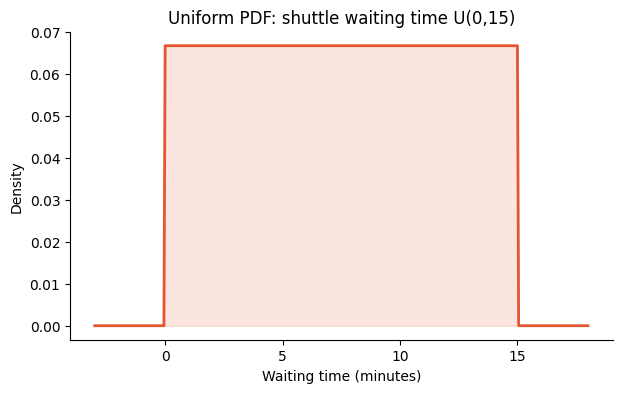

mean = 7.5000, variance = 18.7500


In [9]:
a, b = 0, 15
x = np.linspace(a - 3, b + 3, 400)
pdf = stats.uniform.pdf(x, loc=a, scale=b-a)

fig, ax = plt.subplots()
ax.plot(x, pdf, color=CONTINUOUS_COLOR, linewidth=2)
ax.fill_between(x, pdf, alpha=0.15, color=CONTINUOUS_COLOR)
ax.set_xlabel("Waiting time (minutes)")
ax.set_ylabel("Density")
ax.set_title("Uniform PDF: shuttle waiting time U(0,15)")
plt.show()

mean = stats.uniform.mean(loc=a, scale=b-a)
var = stats.uniform.var(loc=a, scale=b-a)
print(f"mean = {mean:.4f}, variance = {var:.4f}")